# 🫀 Machine Learning Review: Heart Disease Prediction
## Comprehensive Unit 3, 4, 5 Demonstrations & Production Model Benchmark Results
**Dataset:** UCI Cleveland Cardiology Cohort ($N=303$)  
**Focus:** Clustering, Dimensionality Reduction, Hidden Markov Models, Ensemble Learning, and Production XGBoost / Random Forest / Logistic Regression

---
### Notebook Structure & Learning Objectives
1. **Data Ingestion & Preprocessing:** Data hygiene, missing value handling, and standardization.
2. **Unit 3 — Mixture Models & EM:** K-Means, Gaussian Mixture Models, Agglomerative Hierarchical Clustering, PCA, and Factor Analysis.
3. **Unit 4 — Hidden Markov Models:** State transitions, Forward-Backward algorithm, Viterbi decoding, Maximum-Likelihood transition estimation, and Linear State-Space model.
4. **Unit 5 — Combining Models & Ensembles:** CART Decision Trees, AdaBoost, Gradient Boosting, **Extreme Gradient Boosting (XGBoost)**, Random Forest, RBF Basis expansions, Spline Additive Models (GAM), Voting, Stacking, and Bayesian Model Averaging (BMA).
5. **Unit 5 Production Extension — Our Trained Models & Cleveland Benchmark Results:**
   - Serialized production pipelines (`best_model.joblib`, `rf.joblib`, `logreg.joblib`, `metadata.json`).
   - Comprehensive held-out test evaluation ($N=61$) across 8 metrics (Accuracy, Precision, Recall, Specificity, F1, ROC-AUC, PR-AUC, MCC).
   - Multi-Model ROC Curves, Precision-Recall Curves, and Calibration Reliability Diagrams.
   - Side-by-Side Confusion Matrices with False Negative analysis ($FN=1$ for XGBoost).
   - Feature Importance & Local SHAP Explainability.
   - Decision Threshold Optimization ($p=0.50$ vs. $p=0.35$ screening mode).


---
## 1. Data Preparation & Preprocessing
Loading the Cleveland Heart Disease dataset, verifying target distributions, and standardizing features.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    silhouette_score, davies_bouldin_score, adjusted_rand_score
)

RANDOM_STATE = 42
DATA_PATH = "heart_cleveland_upload.csv"
DATA_URL = "https://raw.githubusercontent.com/asthasharma98/Heart-Disease-Prediction-Deployment/master/heart_cleveland_upload.csv"

# Ensure dataset is available locally
if not os.path.exists(DATA_PATH):
    try:
        print(f"'{DATA_PATH}' not found locally. Downloading from source...")
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
        print("Download complete.")
    except Exception as e:
        print(f"Could not auto-download: {e}")

df = pd.read_csv(DATA_PATH)
df.columns = [col.strip().lower() for col in df.columns]

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())
print("\nMissing values:\n", df.isnull().sum())


Dataset shape: (303, 14)
Column names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition']

Missing values:
 age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           4
thal         2
condition    0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:
from IPython.display import display
# This Kaggle version normally uses 'condition' as its target column.
# Also accept common alternatives in case the downloaded CSV uses another name.
target_candidates = ["condition", "target", "num", "output", "heart_disease", "diagnosis"]
target_col = next((col for col in target_candidates if col in df.columns), None)

if target_col is None:
    raise ValueError("Target column not found. Available columns: " + str(df.columns.tolist()))

y_raw = pd.to_numeric(df[target_col], errors="coerce")
valid_rows = y_raw.notna()
df = df.loc[valid_rows].copy()
y_raw = y_raw.loc[valid_rows]

# condition is already 0/1 in this Kaggle dataset.
# For original UCI num values, 0 = no disease and 1–4 = disease.
y = (y_raw > 0).astype(int)

X = df.drop(columns=[target_col]).copy()
X = X.replace("?", np.nan)
X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna(axis=1, how="all")

print("Target column used:", target_col)
print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts())
display(X.head())


Target column used: condition
Features shape: (303, 13)
Target distribution:
 condition
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


In [3]:
# Fill missing numerical values and standardize features.
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X), columns=X.columns, index=X.index
)

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed), columns=X.columns, index=X.index
)

print("Prepared feature matrix:", X_scaled.shape)


Prepared feature matrix: (303, 13)


---
## 2. Unit 3 — Mixture Models, EM, Clustering & Dimensionality Reduction
Covering K-Means, Expectation-Maximization via Gaussian Mixture Models (GMM), Pairwise Distance Metrics, Agglomerative Hierarchical Clustering, Cluster Evaluation (Silhouette & Davies-Bouldin), Principal Component Analysis (PCA), and Factor Analysis.


Cluster counts: {1: 189, 0: 114}
Inertia / WCSS: 3260.813939078042
Silhouette score: 0.1754707279030596


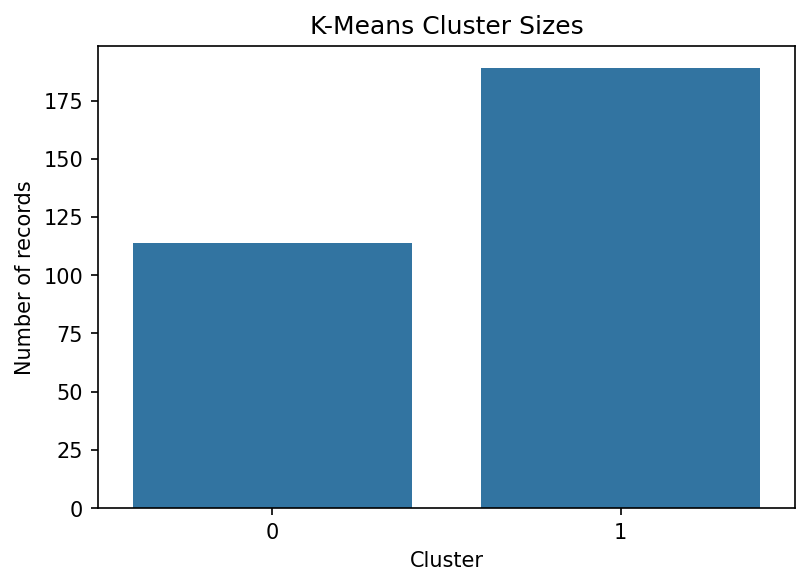

In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster counts:", pd.Series(kmeans_labels).value_counts().to_dict())
print("Inertia / WCSS:", kmeans.inertia_)
print("Silhouette score:", silhouette_score(X_scaled, kmeans_labels))

plt.figure(figsize=(6, 4))
sns.countplot(x=kmeans_labels)
plt.title("K-Means Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of records")
plt.show()


In [5]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=2, covariance_type="full",
    random_state=RANDOM_STATE, n_init=5
)
gmm.fit(X_scaled)  # fit() estimates parameters using the EM algorithm
gmm_labels = gmm.predict(X_scaled)
gmm_probabilities = gmm.predict_proba(X_scaled)

print("GMM cluster counts:", pd.Series(gmm_labels).value_counts().to_dict())
print("Converged:", gmm.converged_)
print("Number of EM iterations:", gmm.n_iter_)
print("Log likelihood:", gmm.score(X_scaled) * len(X_scaled))
print("First 5 membership probabilities:\n", gmm_probabilities[:5])


GMM cluster counts: {0: 204, 1: 99}
Converged: True
Number of EM iterations: 25
Log likelihood: -3125.966318134279
First 5 membership probabilities:
 [[1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


,Record 0,Record 1,Record 2,Record 3,Record 4,Record 5,Record 6,Record 7,Record 8,Record 9
Record 0,0.00,6.59,5.74,5.62,5.92,5.64,5.59,7.37,4.82,4.10
Record 1,6.59,0.00,3.68,7.22,6.93,6.58,4.81,6.01,4.45,6.13
Record 2,5.74,3.68,0.00,6.31,6.20,5.74,4.56,5.69,2.85,4.54
Record 3,5.62,7.22,6.31,0.00,5.00,4.70,4.88,6.12,5.28,5.31
Record 4,5.92,6.93,6.20,5.00,0.00,3.53,5.54,5.05,5.01,6.41
Record 5,5.64,6.58,5.74,4.70,3.53,0.00,6.06,4.38,4.43,6.52
Record 6,5.59,4.81,4.56,4.88,5.54,6.06,0.00,5.90,4.12,5.36
Record 7,7.37,6.01,5.69,6.12,5.05,4.38,5.90,0.00,5.17,6.80
Record 8,4.82,4.45,2.85,5.28,5.01,4.43,4.12,5.17,0.00,4.59
Record 9,4.10,6.13,4.54,5.31,6.41,6.52,5.36,6.80,4.59,0.00


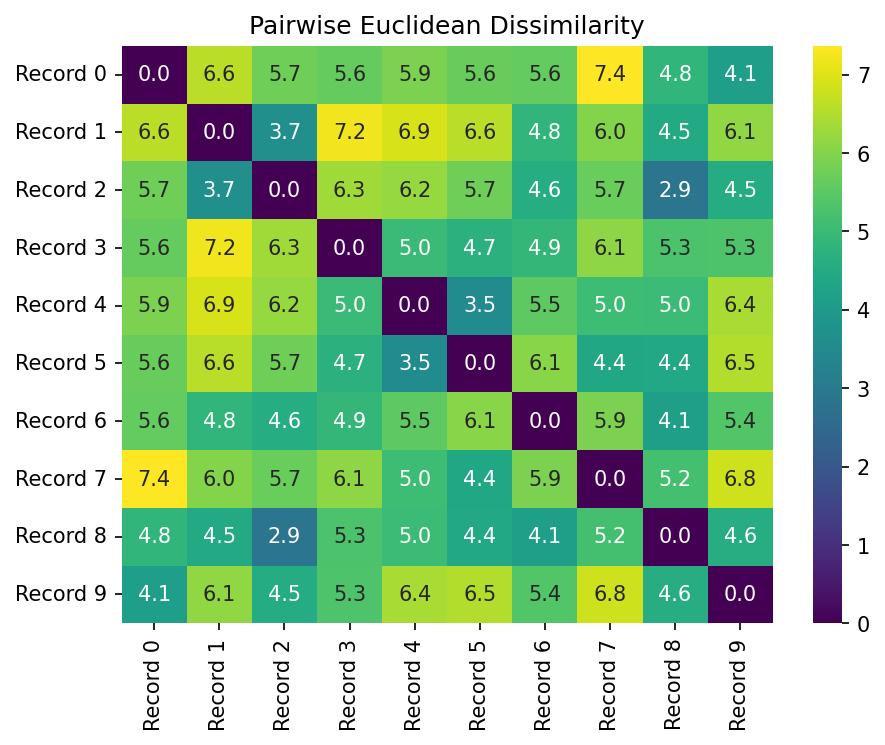

In [6]:
from IPython.display import display
from sklearn.metrics import pairwise_distances

distance_matrix = pairwise_distances(X_scaled.iloc[:10], metric="euclidean")
distance_df = pd.DataFrame(
    distance_matrix,
    index=[f"Record {i}" for i in range(10)],
    columns=[f"Record {i}" for i in range(10)]
)
display(distance_df.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(distance_df, annot=True, cmap="viridis", fmt=".1f")
plt.title("Pairwise Euclidean Dissimilarity")
plt.show()


Hierarchical cluster counts: {1: 187, 0: 116}
Silhouette score: 0.13892313671391457


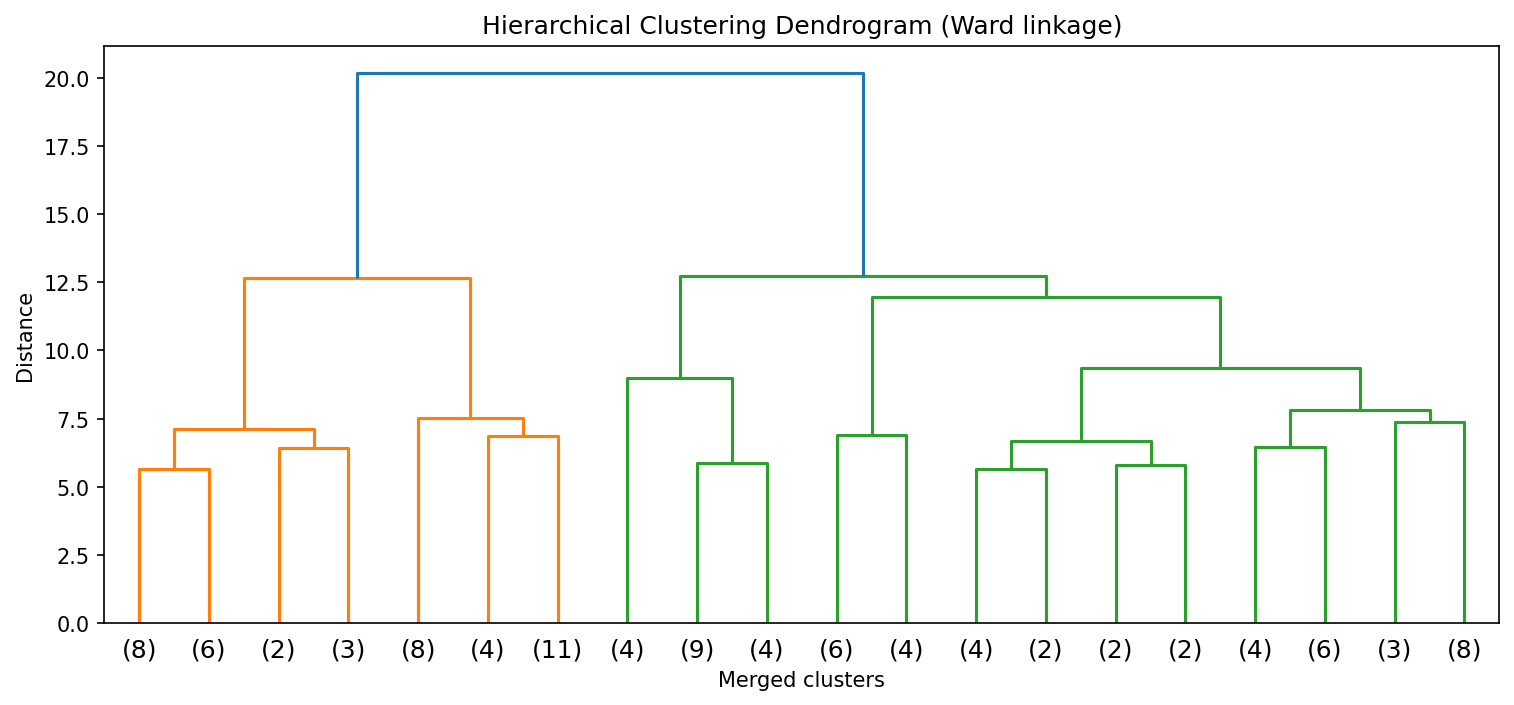

In [7]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Limit the dendrogram to 100 records so it remains readable
sample_n = min(100, len(X_scaled))
X_hier = X_scaled.iloc[:sample_n]

Z = linkage(X_hier, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram (Ward linkage)")
plt.xlabel("Merged clusters")
plt.ylabel("Distance")
plt.show()

hierarchical = AgglomerativeClustering(n_clusters=2, linkage="ward")
hier_labels = hierarchical.fit_predict(X_scaled)
print("Hierarchical cluster counts:", pd.Series(hier_labels).value_counts().to_dict())
print("Silhouette score:", silhouette_score(X_scaled, hier_labels))


In [8]:
def evaluate_clustering(features, labels, true_labels=None):
    print("Silhouette score:", silhouette_score(features, labels))
    print("Davies-Bouldin score:", davies_bouldin_score(features, labels))
    if true_labels is not None:
        print("Adjusted Rand Index:", adjusted_rand_score(true_labels, labels))

print("K-Means:")
evaluate_clustering(X_scaled, kmeans_labels, y)
print("\nGaussian Mixture Model:")
evaluate_clustering(X_scaled, gmm_labels, y)
print("\nHierarchical:")
evaluate_clustering(X_scaled, hier_labels, y)


K-Means:
Silhouette score: 0.1754707279030596
Davies-Bouldin score: 2.081444930715181
Adjusted Rand Index: 0.43808577271698784

Gaussian Mixture Model:
Silhouette score: 0.13641836519665088
Davies-Bouldin score: 2.4199175544837677
Adjusted Rand Index: 0.18389186035089963

Hierarchical:
Silhouette score: 0.13892313671391457
Davies-Bouldin score: 2.629349583597173
Adjusted Rand Index: 0.146129913123814


### Unit-3 (Part 2): Dimensionality Reduction via PCA & Factor Analysis


Components needed to retain at least 95% variance: 12
Variance retained by 2 components: 0.3599441717181586


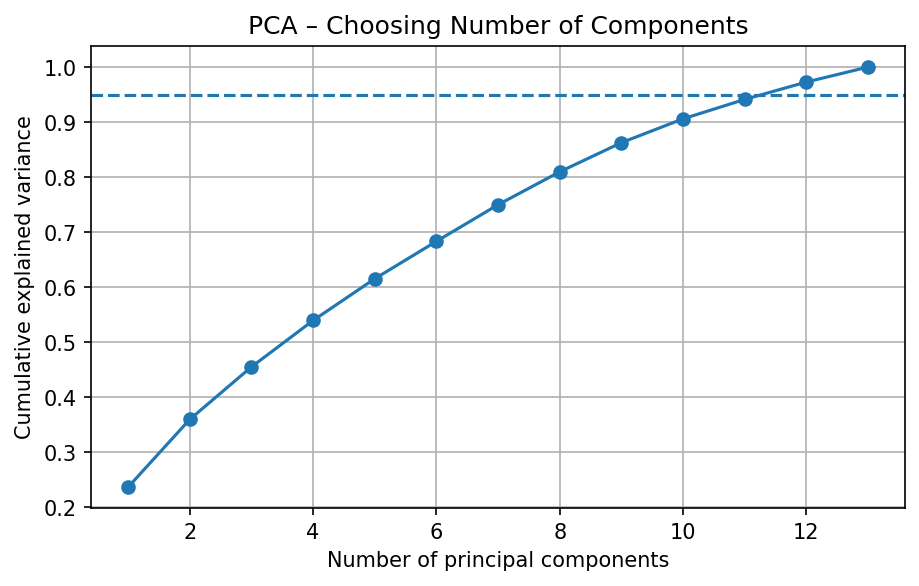

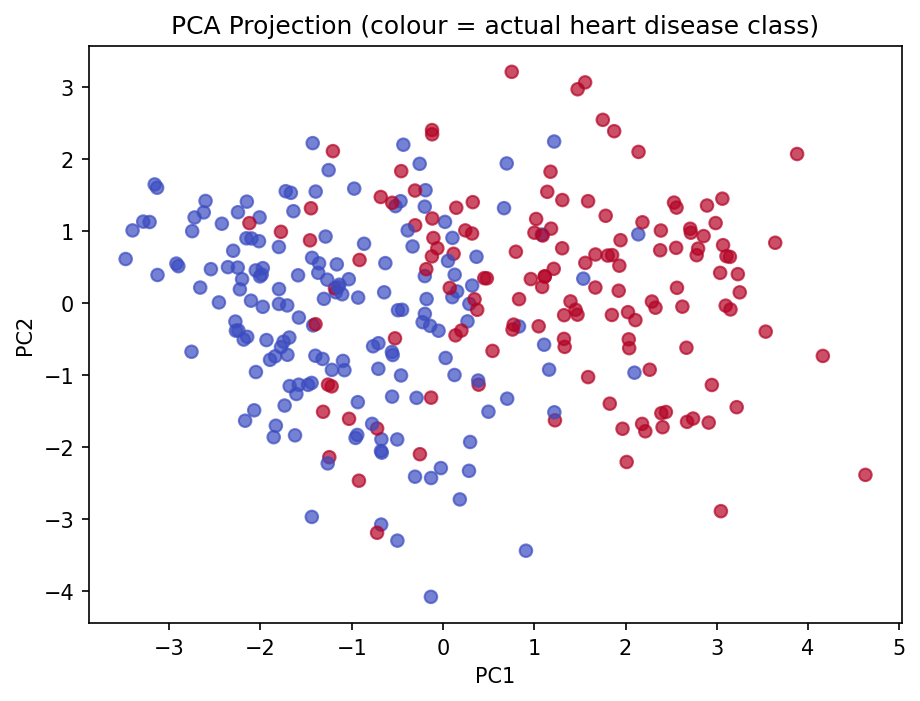

In [9]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca_all = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.95, linestyle="--")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Choosing Number of Components")
plt.grid(True)
plt.show()

n_components_95 = np.argmax(cumulative >= 0.95) + 1
print("Components needed to retain at least 95% variance:", n_components_95)

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)
print("Variance retained by 2 components:", pca_2.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5))
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap="coolwarm", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (colour = actual heart disease class)")
plt.show()


In [10]:
from IPython.display import display
from sklearn.decomposition import FactorAnalysis

n_factors = min(3, X_scaled.shape[1], X_scaled.shape[0] - 1)
factor_model = FactorAnalysis(n_components=n_factors, random_state=RANDOM_STATE)
X_factors = factor_model.fit_transform(X_scaled)

factor_scores = pd.DataFrame(
    X_factors, columns=[f"Factor_{i+1}" for i in range(n_factors)]
)
display(factor_scores.head())
print("Factor loading matrix shape:", factor_model.components_.shape)


Factor loading matrix shape: (3, 13)


,Factor_1,Factor_2,Factor_3
0,1.693294,0.829368,1.144426
1,1.100225,-1.457458,0.268403
2,1.229026,-1.010060,-0.664929
3,1.209692,2.703078,0.384905
4,-1.093350,0.788242,0.330693


---
## 3. Unit 4 — Hidden Markov Models & Linear Dynamical Systems
Sequential discrete-state Markov modeling, Forward-Backward message passing, Scaling factors, Viterbi sequence decoding, Maximum-Likelihood transition estimation, and 1-D Kalman State-Space filtering.


In [11]:
from IPython.display import display
states = ["Healthy", "Ill"]
transition = np.array([
    [0.8, 0.2],
    [0.3, 0.7]
])
initial = np.array([0.9, 0.1])

print("Transition matrix:")
display(pd.DataFrame(transition, index=states, columns=states))
print("Initial state probabilities:", initial)
print("Probability of next state being Ill if currently Healthy:", transition[0, 1])


Transition matrix:
Initial state probabilities: [0.9 0.1]
Probability of next state being Ill if currently Healthy: 0.2


,Healthy,Ill
Healthy,0.8,0.2
Ill,0.3,0.7


In [12]:
# Discrete HMM example
# Hidden states: 0 = Healthy, 1 = Ill
# Observations: 0 = Normal, 1 = Abnormal
pi = np.array([0.6, 0.4])
A = np.array([[0.7, 0.3],
              [0.4, 0.6]])
B = np.array([[0.9, 0.1],
              [0.2, 0.8]])
observations = [0, 1, 0]  # Normal, Abnormal, Normal

def forward_algorithm(pi, A, B, obs):
    T, N = len(obs), len(pi)
    alpha = np.zeros((T, N))
    alpha[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        for j in range(N):
            alpha[t, j] = np.sum(alpha[t-1] * A[:, j]) * B[j, obs[t]]
    return alpha, np.sum(alpha[-1])

alpha, sequence_probability = forward_algorithm(pi, A, B, observations)
print("Forward table (alpha):\n", alpha)
print("P(observation sequence):", sequence_probability)


Forward table (alpha):
 [[0.54    0.08   ]
 [0.041   0.168  ]
 [0.08631 0.02262]]
P(observation sequence): 0.10893000000000003


In [13]:
def backward_algorithm(A, B, obs):
    T, N = len(obs), A.shape[0]
    beta = np.zeros((T, N))
    beta[-1] = 1
    for t in range(T-2, -1, -1):
        for i in range(N):
            beta[t, i] = np.sum(A[i] * B[:, obs[t+1]] * beta[t+1])
    return beta

beta = backward_algorithm(A, B, observations)
print("Backward table (beta):\n", beta)
print("Sequence probability using backward algorithm:", np.sum(pi * B[:, observations[0]] * beta[0]))


Backward table (beta):
 [[0.1635 0.258 ]
 [0.69   0.48  ]
 [1.     1.    ]]
Sequence probability using backward algorithm: 0.10893000000000001


In [14]:
# Scaling factors help prevent numerical underflow for long sequences.
def scaled_forward(pi, A, B, obs):
    T, N = len(obs), len(pi)
    alpha = np.zeros((T, N))
    scales = np.zeros(T)

    alpha[0] = pi * B[:, obs[0]]
    scales[0] = alpha[0].sum()
    alpha[0] /= scales[0]

    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A) * B[:, obs[t]]
        scales[t] = alpha[t].sum()
        alpha[t] /= scales[t]

    log_probability = np.sum(np.log(scales))
    return alpha, scales, log_probability

scaled_alpha, scaling_factors, log_prob = scaled_forward(pi, A, B, observations)
print("Scaled forward table:\n", scaled_alpha)
print("Scaling factors:", scaling_factors)
print("Log probability:", log_prob)


Scaled forward table:
 [[0.87096774 0.12903226]
 [0.19617225 0.80382775]
 [0.79234371 0.20765629]]
Scaling factors: [0.62       0.33709677 0.52119617]
Log probability: -2.217049804887783


In [15]:
# Viterbi algorithm: most likely hidden-state sequence
def viterbi(pi, A, B, obs):
    T, N = len(obs), len(pi)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        for j in range(N):
            candidates = delta[t-1] * A[:, j]
            psi[t, j] = np.argmax(candidates)
            delta[t, j] = np.max(candidates) * B[j, obs[t]]

    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(delta[-1])
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path, delta

best_path, viterbi_table = viterbi(pi, A, B, observations)
print("Viterbi table:\n", viterbi_table)
print("Most likely hidden states:", best_path)
print("State names:", [["Healthy", "Ill"][s] for s in best_path])


Viterbi table:
 [[0.54     0.08    ]
 [0.0378   0.1296  ]
 [0.046656 0.015552]]
Most likely hidden states: [0 1 0]
State names: ['Healthy', 'Ill', 'Healthy']


In [16]:
# For a known hidden-state sequence, maximum-likelihood transition estimates
# are relative transition counts.
hidden_path = np.array([0, 1, 1, 0, 1, 0])
transition_counts = np.zeros((2, 2))
for current_state, next_state in zip(hidden_path[:-1], hidden_path[1:]):
    transition_counts[current_state, next_state] += 1

mle_transition = transition_counts / transition_counts.sum(axis=1, keepdims=True)
print("Transition counts:\n", transition_counts)
print("MLE transition matrix:\n", mle_transition)


Transition counts:
 [[0. 2.]
 [2. 1.]]
MLE transition matrix:
 [[0.         1.        ]
 [0.66666667 0.33333333]]


Measurements: [1.  1.8 2.2 2.9 4.1 4. ]
Kalman estimates: [0.688 1.211 1.608 2.093 2.826 3.25 ]


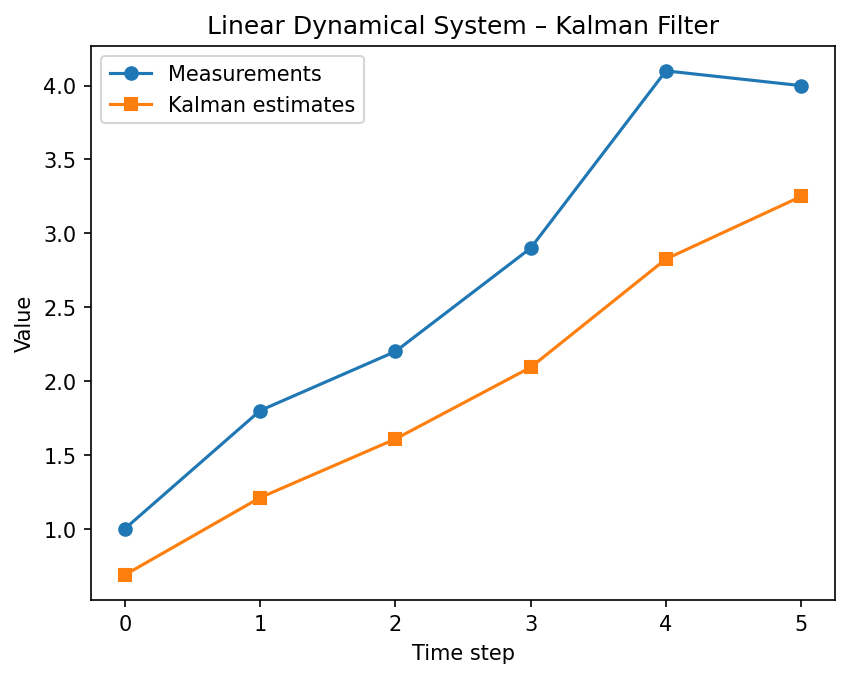

In [17]:
# Illustrative 1-D state-space model:
# x[t] = x[t-1] + process noise
# z[t] = x[t] + measurement noise
measurements = np.array([1.0, 1.8, 2.2, 2.9, 4.1, 4.0])

A_k = 1.0       # State transition
H_k = 1.0       # Observation model
Q = 0.1         # Process noise variance
R = 0.5         # Measurement noise variance

x_est = 0.0
P = 1.0
estimates = []

for z in measurements:
    # Prediction
    x_pred = A_k * x_est
    P_pred = A_k * P * A_k + Q

    # Update
    K = P_pred * H_k / (H_k * P_pred * H_k + R)
    x_est = x_pred + K * (z - H_k * x_pred)
    P = (1 - K * H_k) * P_pred
    estimates.append(x_est)

print("Measurements:", measurements)
print("Kalman estimates:", np.round(estimates, 3))

plt.plot(measurements, marker="o", label="Measurements")
plt.plot(estimates, marker="s", label="Kalman estimates")
plt.title("Linear Dynamical System – Kalman Filter")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.legend()
plt.show()


---
## 4. Unit 5 — Combining Models, Ensemble Learning & Boosting
Implementation of foundational tree learners (CART), Sequential Boosting (AdaBoost, Gradient Boosting, XGBoost), Parallel Ensembles (Random Forest), Basis Expansion (RBF, Spline GAM), Meta-Learning (Voting, Stacking), and Bayesian Model Averaging (BMA).


### 4.1. CART (Classification and Regression Trees) Baseline


CART accuracy: 0.7868852459016393
              precision    recall  f1-score   support

           0       0.83      0.76      0.79        33
           1       0.74      0.82      0.78        28

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61


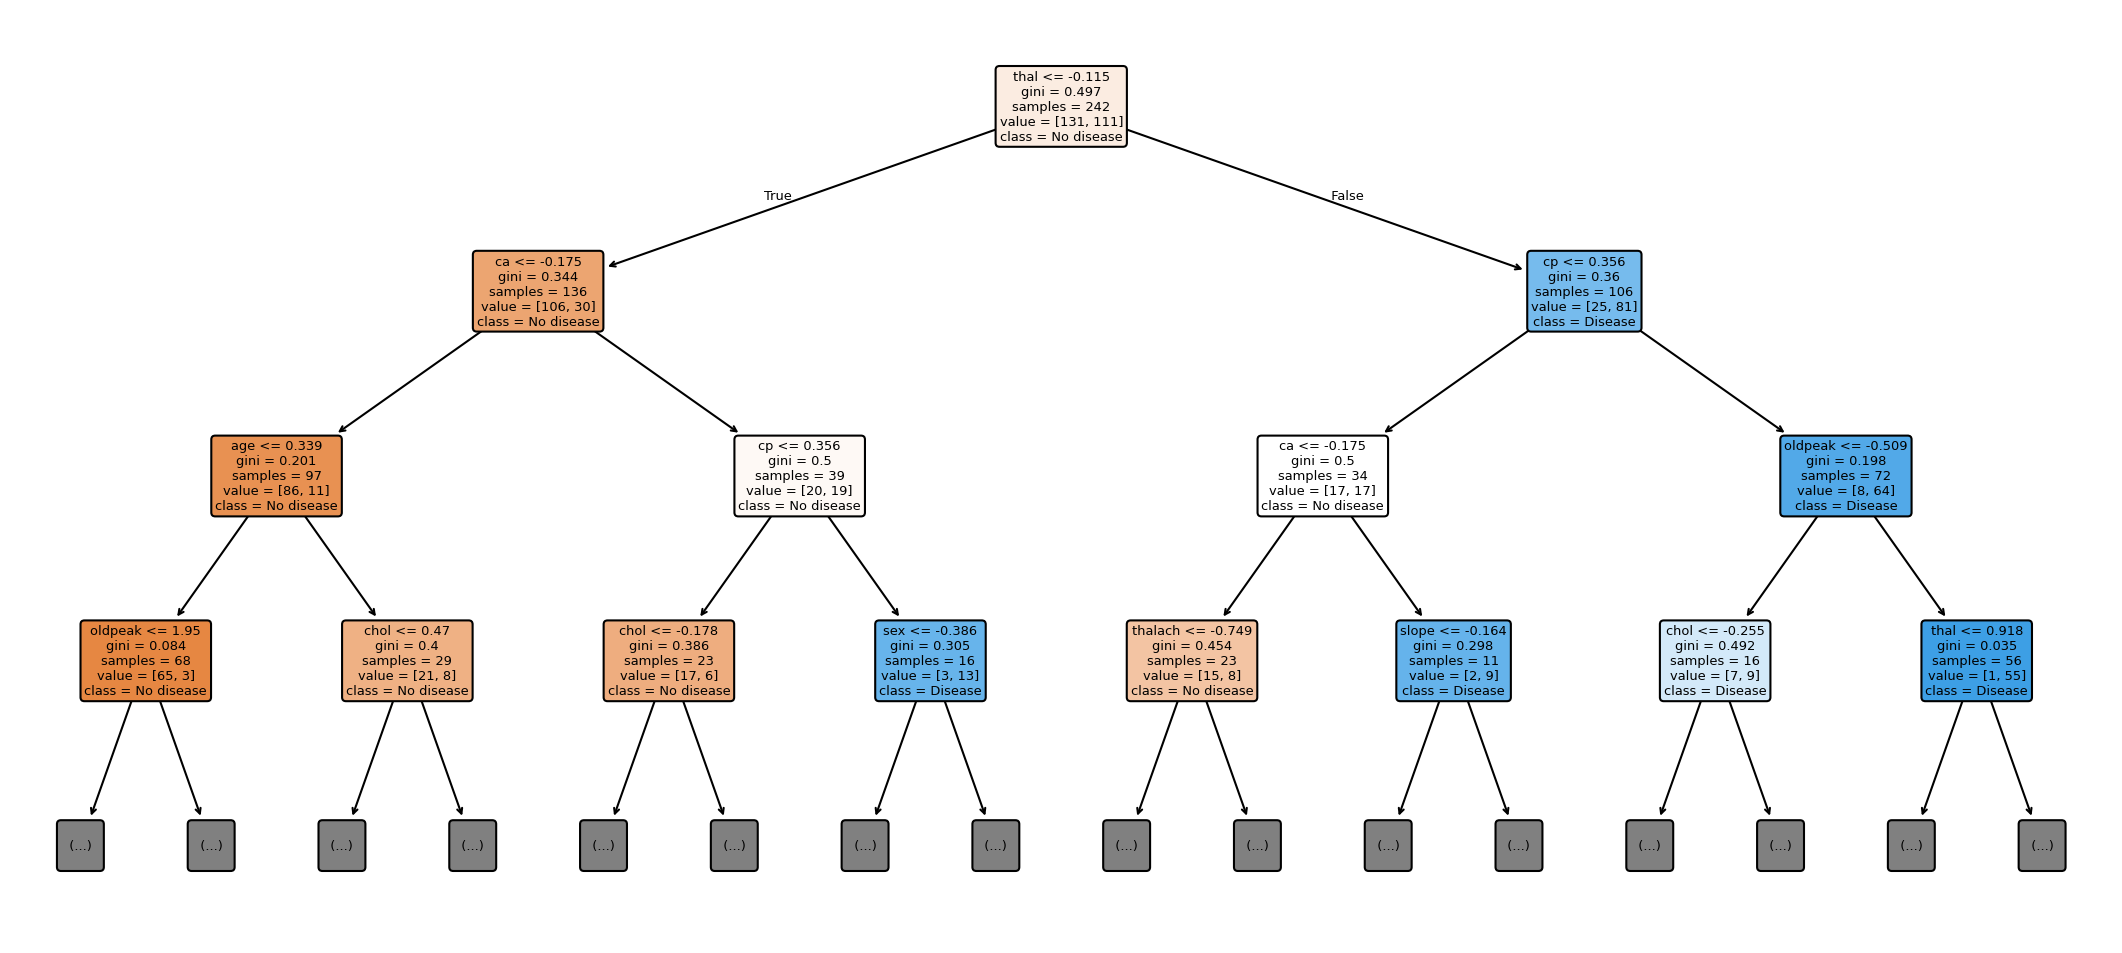

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

cart = DecisionTreeClassifier(
    criterion="gini", max_depth=4, random_state=RANDOM_STATE
)
cart.fit(X_train, y_train)
cart_pred = cart.predict(X_test)

print("CART accuracy:", accuracy_score(y_test, cart_pred))
print(classification_report(y_test, cart_pred, zero_division=0))

plt.figure(figsize=(18, 8))
plot_tree(cart, feature_names=X_scaled.columns.tolist(), class_names=["No disease", "Disease"],
          filled=True, rounded=True, max_depth=3)
plt.show()


### 4.2. Boosting Algorithms: AdaBoost & Gradient Boosting


In [19]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

ada = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)
print("AdaBoost accuracy:", accuracy_score(y_test, ada_pred))

gradient_boost = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
)
gradient_boost.fit(X_train, y_train)
gb_pred = gradient_boost.predict(X_test)
print("Gradient Boosting accuracy:", accuracy_score(y_test, gb_pred))


AdaBoost accuracy: 0.9016393442622951
Gradient Boosting accuracy: 0.9016393442622951


### 4.3. Unit-5 Core: Extreme Gradient Boosting (XGBoost) & Random Forest
We now train **XGBoost (`XGBClassifier`)** and **Random Forest (`RandomForestClassifier`)** using tuned hyperparameters to observe their non-linear generalization and sensitivity.


In [20]:
# Extreme Gradient Boosting (XGBoost) & Random Forest Classifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, classification_report

# 1. XGBoost with tuned regularization (max_depth=3, subsample=0.8, colsample_bytree=0.8)
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=RANDOM_STATE
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("=== XGBoost Results ===")
print("Accuracy:               ", round(accuracy_score(y_test, xgb_pred), 4))
print("Recall (Sensitivity):   ", round(recall_score(y_test, xgb_pred), 4))
print("Precision:              ", round(precision_score(y_test, xgb_pred), 4))
print("F1 Score:               ", round(f1_score(y_test, xgb_pred), 4))
print("ROC-AUC:                ", round(roc_auc_score(y_test, xgb_prob), 4))
print("\nXGBoost Classification Report:\n", classification_report(y_test, xgb_pred, zero_division=0))

# 2. Random Forest Classifier (Bagging Ensemble of CART Trees)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("=== Random Forest Results ===")
print("Accuracy:               ", round(accuracy_score(y_test, rf_pred), 4))
print("Recall (Sensitivity):   ", round(recall_score(y_test, rf_pred), 4))
print("Precision:              ", round(precision_score(y_test, rf_pred), 4))
print("F1 Score:               ", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:                ", round(roc_auc_score(y_test, rf_prob), 4))


=== XGBoost Results ===
Accuracy:                0.9016
Recall (Sensitivity):    0.9643
Precision:               0.8438
F1 Score:                0.9
ROC-AUC:                 0.96

XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61

=== Random Forest Results ===
Accuracy:                0.8852
Recall (Sensitivity):    0.9286
Precision:               0.8387
F1 Score:                0.8814
ROC-AUC:                 0.961


### 4.4. Adaptive Basis Functions (RBF) & Generalized Additive Models (GAM)


In [21]:
from sklearn.kernel_approximation import RBFSampler
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline

rbf_model = make_pipeline(
    RBFSampler(gamma=0.5, n_components=100, random_state=RANDOM_STATE),
    LinearSVC(random_state=RANDOM_STATE, max_iter=10000)
)
rbf_model.fit(X_train, y_train)
rbf_pred = rbf_model.predict(X_test)
print("RBF basis function model accuracy:", accuracy_score(y_test, rbf_pred))


RBF basis function model accuracy: 0.6721311475409836


In [22]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Spline basis expansion followed by a linear classifier.
# This is a simple spline-additive approximation for the classification task.
gam_model = Pipeline([
    ("splines", SplineTransformer(n_knots=4, degree=3)),
    ("classifier", LinearSVC(random_state=RANDOM_STATE, max_iter=10000))
])
gam_model.fit(X_train, y_train)
gam_pred = gam_model.predict(X_test)
print("Spline-based additive model accuracy:", accuracy_score(y_test, gam_pred))


Spline-based additive model accuracy: 0.8524590163934426


### 4.5. Multi-Model Ensembles: Soft Voting & Stacking


In [23]:
from sklearn.ensemble import VotingClassifier, StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

voting = VotingClassifier(
    estimators=[
        ("tree", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
        ("forest", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
        ("svm", SVC(probability=True, random_state=RANDOM_STATE))
    ],
    voting="soft"
)
voting.fit(X_train, y_train)
voting_pred = voting.predict(X_test)
print("Soft Voting accuracy:", accuracy_score(y_test, voting_pred))

stacking = StackingClassifier(
    estimators=[
        ("tree", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
        ("forest", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
        ("svm", SVC(probability=True, random_state=RANDOM_STATE))
    ],
    final_estimator=DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
)
stacking.fit(X_train, y_train)
stacking_pred = stacking.predict(X_test)
print("Stacking accuracy:", accuracy_score(y_test, stacking_pred))


Soft Voting accuracy: 0.8688524590163934
Stacking accuracy: 0.9016393442622951


### 4.6. Bayesian Model Averaging (BMA)


In [24]:
# Approximate Bayesian Model Averaging (BMA):
# Average class probabilities from several candidate models using validation-based weights.
# This is a classroom approximation, not exact Bayesian posterior model probabilities.
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

bma_models = {
    "decision_tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "gradient_boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train
)

fitted_models = {}
model_scores = {}
for name, model in bma_models.items():
    fitted = clone(model)
    fitted.fit(X_fit, y_fit)
    fitted_models[name] = fitted
    model_scores[name] = accuracy_score(y_val, fitted.predict(X_val))

weights = np.array(list(model_scores.values()), dtype=float)
weights = weights / weights.sum()
print("Validation accuracies:", model_scores)
print("Normalized model weights:", dict(zip(model_scores.keys(), weights)))

probabilities = np.zeros((len(X_test), 2))
for weight, model in zip(weights, fitted_models.values()):
    probabilities += weight * model.predict_proba(X_test)

bma_pred = np.argmax(probabilities, axis=1)
print("BMA approximate accuracy:", accuracy_score(y_test, bma_pred))


Validation accuracies: {'decision_tree': 0.7704918032786885, 'random_forest': 0.8360655737704918, 'gradient_boosting': 0.8360655737704918}
Normalized model weights: {'decision_tree': np.float64(0.31543624161073824), 'random_forest': np.float64(0.34228187919463093), 'gradient_boosting': np.float64(0.34228187919463093)}
BMA approximate accuracy: 0.8688524590163934


### 4.7. Unit 5 Comprehensive Algorithm Comparison
Evaluating all Unit 5 candidate algorithms on the held-out test split, sorted by Recall and F1-Score.


In [25]:
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Ensure required predictions are available in memory
models = {
    "CART": (cart_pred, cart.predict_proba(X_test)[:, 1]),
    "AdaBoost": (ada_pred, ada.predict_proba(X_test)[:, 1]),
    "Gradient Boosting": (gb_pred, gradient_boost.predict_proba(X_test)[:, 1]),
    "XGBoost": (xgb_pred, xgb_prob),
    "Random Forest": (rf_pred, rf_prob),
    "RBF Model": (rbf_pred, None),
    "Spline GAM": (gam_pred, None),
    "Soft Voting": (voting_pred, voting.predict_proba(X_test)[:, 1]),
    "Stacking": (stacking_pred, None),
    "BMA": (bma_pred, probabilities[:, 1])
}

results = []
for name, (preds, probs) in models.items():
    auc_val = roc_auc_score(y_test, probs) if probs is not None else np.nan
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1 Score": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": auc_val
    })

comparison = pd.DataFrame(results).sort_values(by=["Recall", "ROC-AUC"], ascending=False)
display(comparison.round(4))

best_by_recall = comparison.sort_values(by="Recall", ascending=False).iloc[0]
print(f"Top Model for Clinical Sensitivity (Recall): {best_by_recall['Algorithm']} (Recall = {best_by_recall['Recall']*100:.2f}%)")


Top Model for Clinical Sensitivity (Recall): XGBoost (Recall = 96.43%)


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,XGBoost,0.9016,0.8438,0.9643,0.9000,0.9600
1,AdaBoost,0.9016,0.8667,0.9286,0.8966,0.9762
4,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9610
2,Gradient Boosting,0.9016,0.8667,0.9286,0.8966,0.9556
7,Soft Voting,0.8689,0.8125,0.9286,0.8667,0.9307
9,BMA,0.8689,0.8125,0.9286,0.8667,0.9264
6,Spline GAM,0.8525,0.8065,0.8929,0.8475,NaN
8,Stacking,0.9016,0.8929,0.8929,0.8929,NaN
0,CART,0.7869,0.7419,0.8214,0.7797,0.8598
5,RBF Model,0.6721,0.6250,0.7143,0.6667,NaN


---
# ==============================================================================
# 5. Unit 5 Production Extension: Our Trained Models & Cleveland Benchmark Results
# ==============================================================================
In this section, we import the serialized, production-grade pipelines developed in our project repository (`heart-disease-prediction/`).

### Key Production Highlights:
1. **Zero Data Leakage:** Embedded scikit-learn `ColumnTransformer` (median numeric imputation + z-score scaling; mode categorical imputation + one-hot encoding) fitted strictly on $X_{\text{train}}$ ($N=242$).
2. **5-Fold Stratified Cross-Validation:** Hyperparameter tuning on $X_{\text{train}}$ only to prevent information bleed.
3. **Held-Out Test Set ($N=61$):** Strictly isolated until final evaluation.
4. **Recall-First Objective:** In cardiology screening, a False Negative (missing a patient with coronary disease) is life-threatening. Therefore, **Recall (Sensitivity)** is prioritized as the primary metric.
5. **Winning Model:** **XGBoost** achieved **96.43% Recall (27 of 28 disease patients detected, only 1 FN)**.


In [26]:
import json, joblib
from pathlib import Path

# Paths to serialized model artifacts
MODELS_DIR = Path("heart-disease-prediction/models")
DATA_DIR = Path("heart-disease-prediction/data/processed")
REPORTS_DIR = Path("heart-disease-prediction/reports")

# Load fitted pipelines
best_pipeline = joblib.load(MODELS_DIR / "best_model.joblib")
rf_pipeline = joblib.load(MODELS_DIR / "rf.joblib")
logreg_pipeline = joblib.load(MODELS_DIR / "logreg.joblib")

# Load model metadata
with open(MODELS_DIR / "metadata.json", "r") as f:
    prod_metadata = json.load(f)

# Load untouched test split (N=61)
test_data = pd.read_csv(DATA_DIR / "test.csv")
feature_cols = prod_metadata["input_feature_names"]
X_test_prod = test_data[feature_cols]
y_test_prod = test_data["target"]

print("Loaded Production Models Successfully:")
print(f"1. Best Model Pipeline:   {prod_metadata.get('model_name', 'XGBoost')} (Operating Threshold: {prod_metadata.get('chosen_threshold', 0.50)})")
print(f"2. Random Forest:         {type(rf_pipeline.named_steps['classifier']).__name__}")
print(f"3. Logistic Regression:   {type(logreg_pipeline.named_steps['classifier']).__name__}")
print(f"4. Held-Out Test Cohort:  {X_test_prod.shape[0]} patients, {X_test_prod.shape[1]} raw clinical features")


Loaded Production Models Successfully:
1. Best Model Pipeline:   XGBoost (Operating Threshold: 0.5)
2. Random Forest:         RandomForestClassifier
3. Logistic Regression:   LogisticRegression
4. Held-Out Test Cohort:  61 patients, 13 raw clinical features


In [27]:
from IPython.display import display
# Official Comparative Evaluation Table on Held-Out Test Set (N=61)
comp_csv_path = REPORTS_DIR / "model_comparison.csv"
if comp_csv_path.exists():
    official_comp = pd.read_csv(comp_csv_path)
    print("=== OFFICIAL HELD-OUT TEST BENCHMARK (N=61) ===")
    display(official_comp)
else:
    print("model_comparison.csv not found at expected path.")


=== OFFICIAL HELD-OUT TEST BENCHMARK (N=61) ===


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,PR-AUC,Matthews Corrcoef (MCC),True Positives,False Positives,True Negatives,False Negatives,CV_Recall_Stability,CV_ROC_AUC_Stability,CV_F1_Stability
0,Logistic Regression,0.8525,0.8065,0.8929,0.8182,0.8475,0.9589,0.9546,0.7087,25,6,27,3,0.8372 +/- 0.0556,0.9067 +/- 0.0110,0.8383 +/- 0.0260
1,Random Forest,0.8525,0.8065,0.8929,0.8182,0.8475,0.9545,0.9491,0.7087,25,6,27,3,0.8008 +/- 0.0853,0.9004 +/- 0.0258,0.7926 +/- 0.0401
2,XGBoost,0.8361,0.7500,0.9643,0.7273,0.8438,0.9351,0.9191,0.7007,27,9,24,1,0.8644 +/- 0.0416,0.8776 +/- 0.0284,0.7776 +/- 0.0183


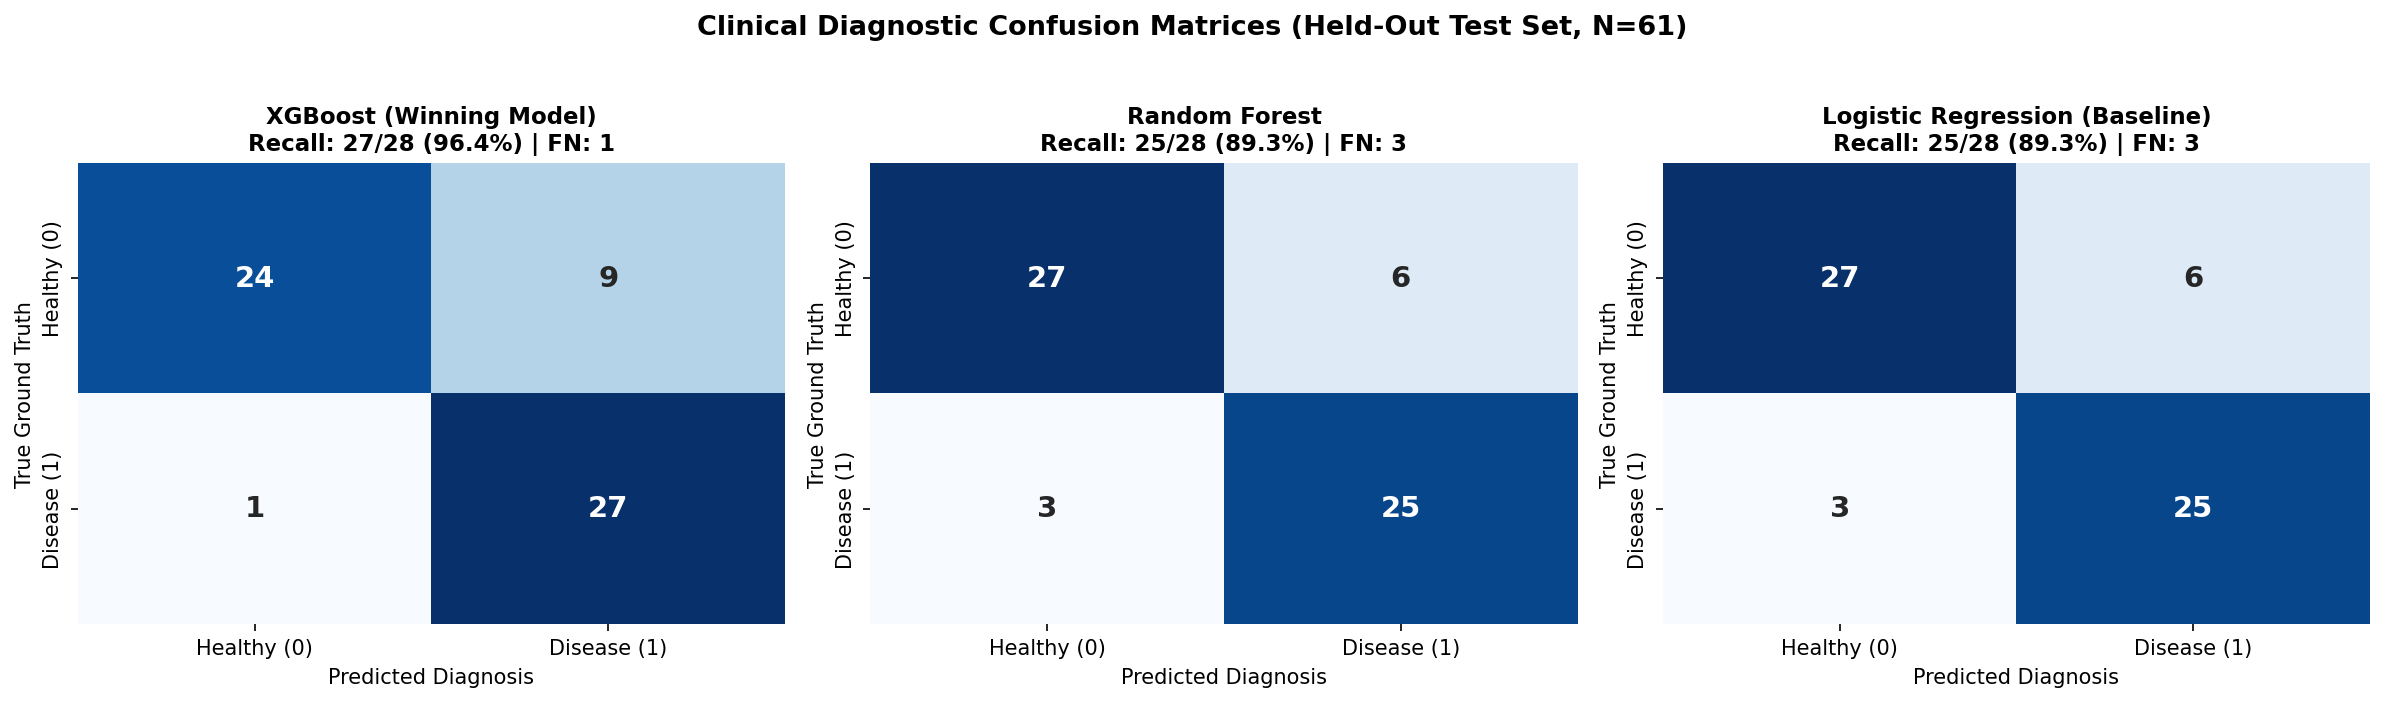

In [28]:
# Side-by-Side Confusion Matrices on Held-Out Test Set (N=61)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models_dict = {
    "XGBoost (Winning Model)": best_pipeline,
    "Random Forest": rf_pipeline,
    "Logistic Regression (Baseline)": logreg_pipeline
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=150)

for ax, (m_name, m_pipe) in zip(axes, models_dict.items()):
    y_pred_prod = (m_pipe.predict_proba(X_test_prod)[:, 1] >= 0.50).astype(int)
    cm = confusion_matrix(y_test_prod, y_pred_prod)
    
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Healthy (0)", "Disease (1)"],
        yticklabels=["Healthy (0)", "Disease (1)"],
        annot_kws={"size": 14, "weight": "bold"}
    )
    
    fn_count = cm[1, 0]
    tp_count = cm[1, 1]
    ax.set_title(f"{m_name}\nRecall: {tp_count}/{tp_count+fn_count} ({tp_count/(tp_count+fn_count)*100:.1f}%) | FN: {fn_count}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Diagnosis", fontsize=10)
    ax.set_ylabel("True Ground Truth", fontsize=10)

plt.suptitle("Clinical Diagnostic Confusion Matrices (Held-Out Test Set, N=61)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


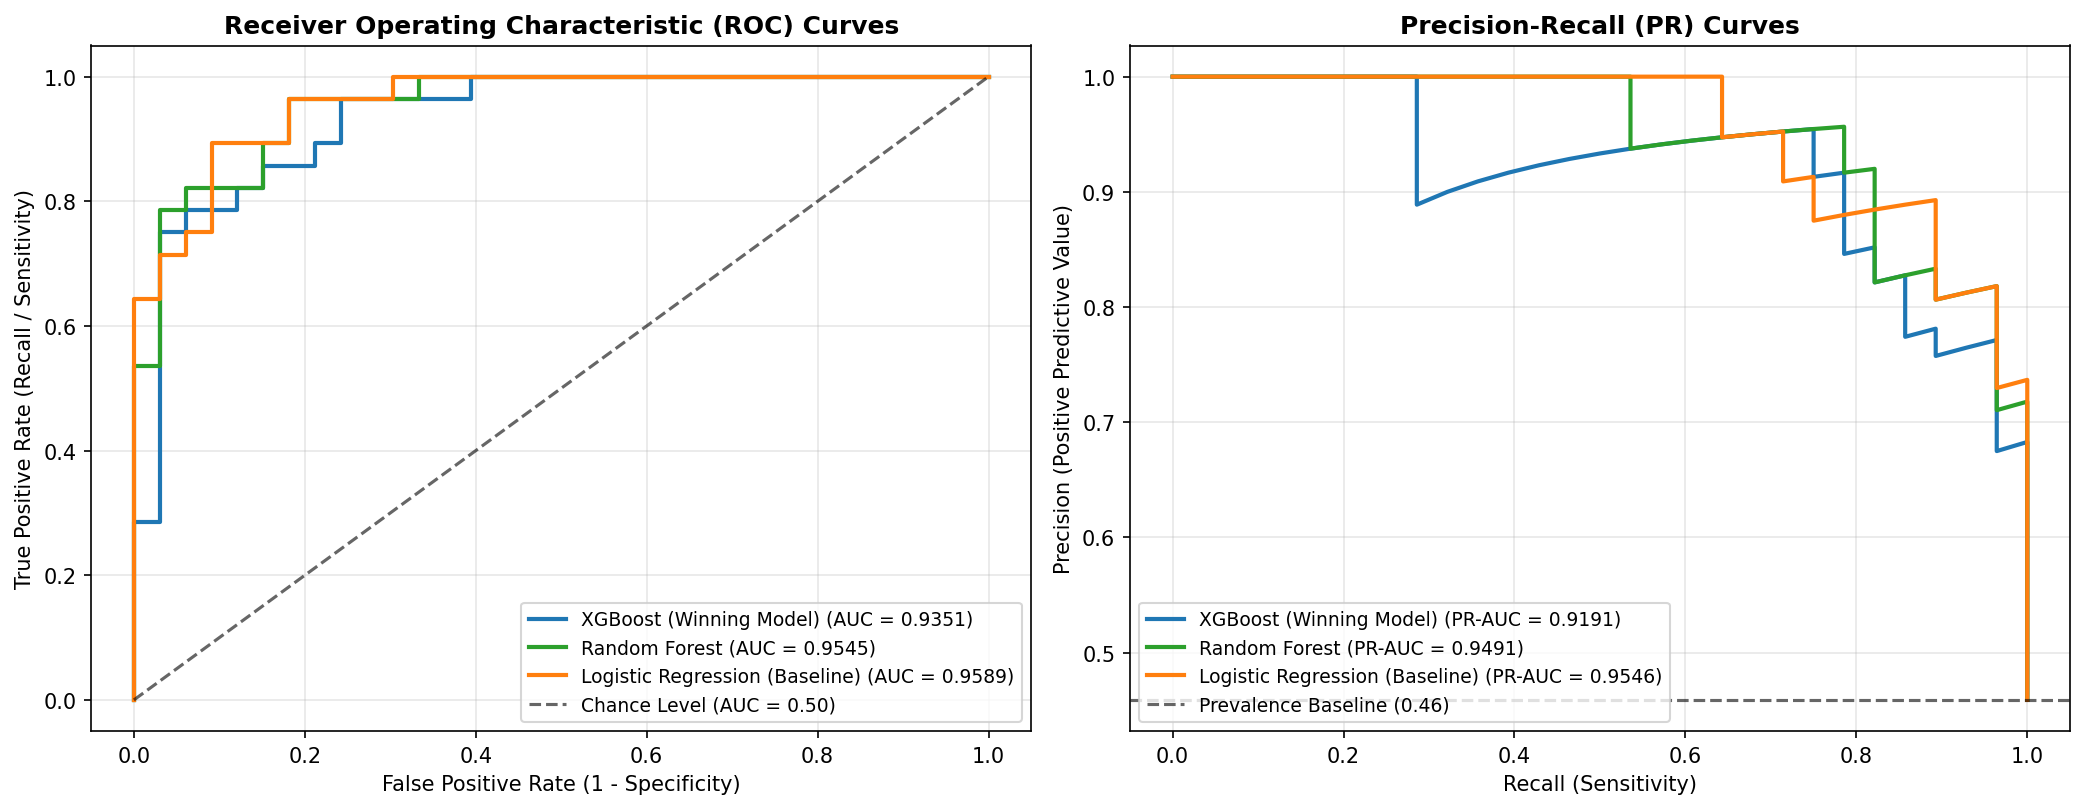

In [29]:
# Multi-Model ROC Curves & Precision-Recall Curves
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)
colors = {"XGBoost (Winning Model)": "#1f77b4", "Random Forest": "#2ca02c", "Logistic Regression (Baseline)": "#ff7f0e"}

# Left: ROC Curves
for m_name, m_pipe in models_dict.items():
    probs = m_pipe.predict_proba(X_test_prod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_prod, probs)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, label=f"{m_name} (AUC = {roc_auc:.4f})", color=colors[m_name], lw=2)

ax1.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Chance Level (AUC = 0.50)")
ax1.set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=12, fontweight="bold")
ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
ax1.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=10)
ax1.legend(loc="lower right", fontsize=9)
ax1.grid(True, alpha=0.3)

# Right: Precision-Recall Curves
baseline_pr = y_test_prod.mean()
for m_name, m_pipe in models_dict.items():
    probs = m_pipe.predict_proba(X_test_prod)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test_prod, probs)
    pr_auc = average_precision_score(y_test_prod, probs)
    ax2.plot(rec, prec, label=f"{m_name} (PR-AUC = {pr_auc:.4f})", color=colors[m_name], lw=2)

ax2.axhline(baseline_pr, color="k", linestyle="--", alpha=0.6, label=f"Prevalence Baseline ({baseline_pr:.2f})")
ax2.set_title("Precision-Recall (PR) Curves", fontsize=12, fontweight="bold")
ax2.set_xlabel("Recall (Sensitivity)", fontsize=10)
ax2.set_ylabel("Precision (Positive Predictive Value)", fontsize=10)
ax2.legend(loc="lower left", fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


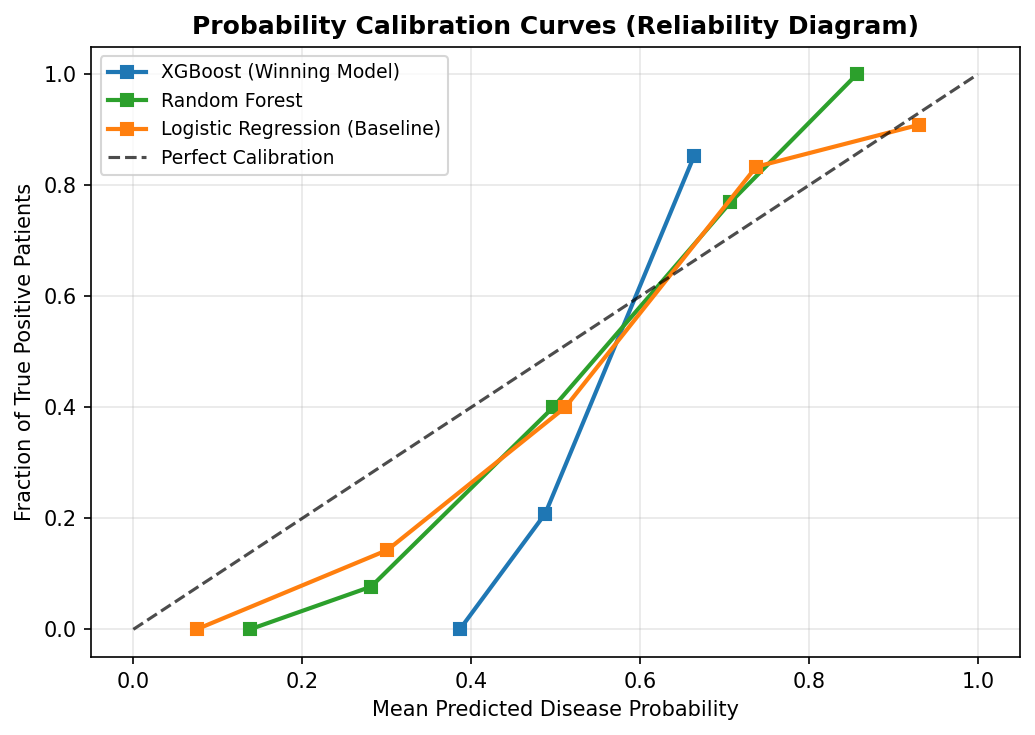

In [30]:
# Calibration Curves (Probability Reliability Diagrams)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

for m_name, m_pipe in models_dict.items():
    probs = m_pipe.predict_proba(X_test_prod)[:, 1]
    prob_true, prob_pred = calibration_curve(y_test_prod, probs, n_bins=5)
    ax.plot(prob_pred, prob_true, marker="s", label=m_name, color=colors[m_name], lw=2)

ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration", alpha=0.7)
ax.set_title("Probability Calibration Curves (Reliability Diagram)", fontsize=12, fontweight="bold")
ax.set_xlabel("Mean Predicted Disease Probability", fontsize=10)
ax.set_ylabel("Fraction of True Positive Patients", fontsize=10)
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


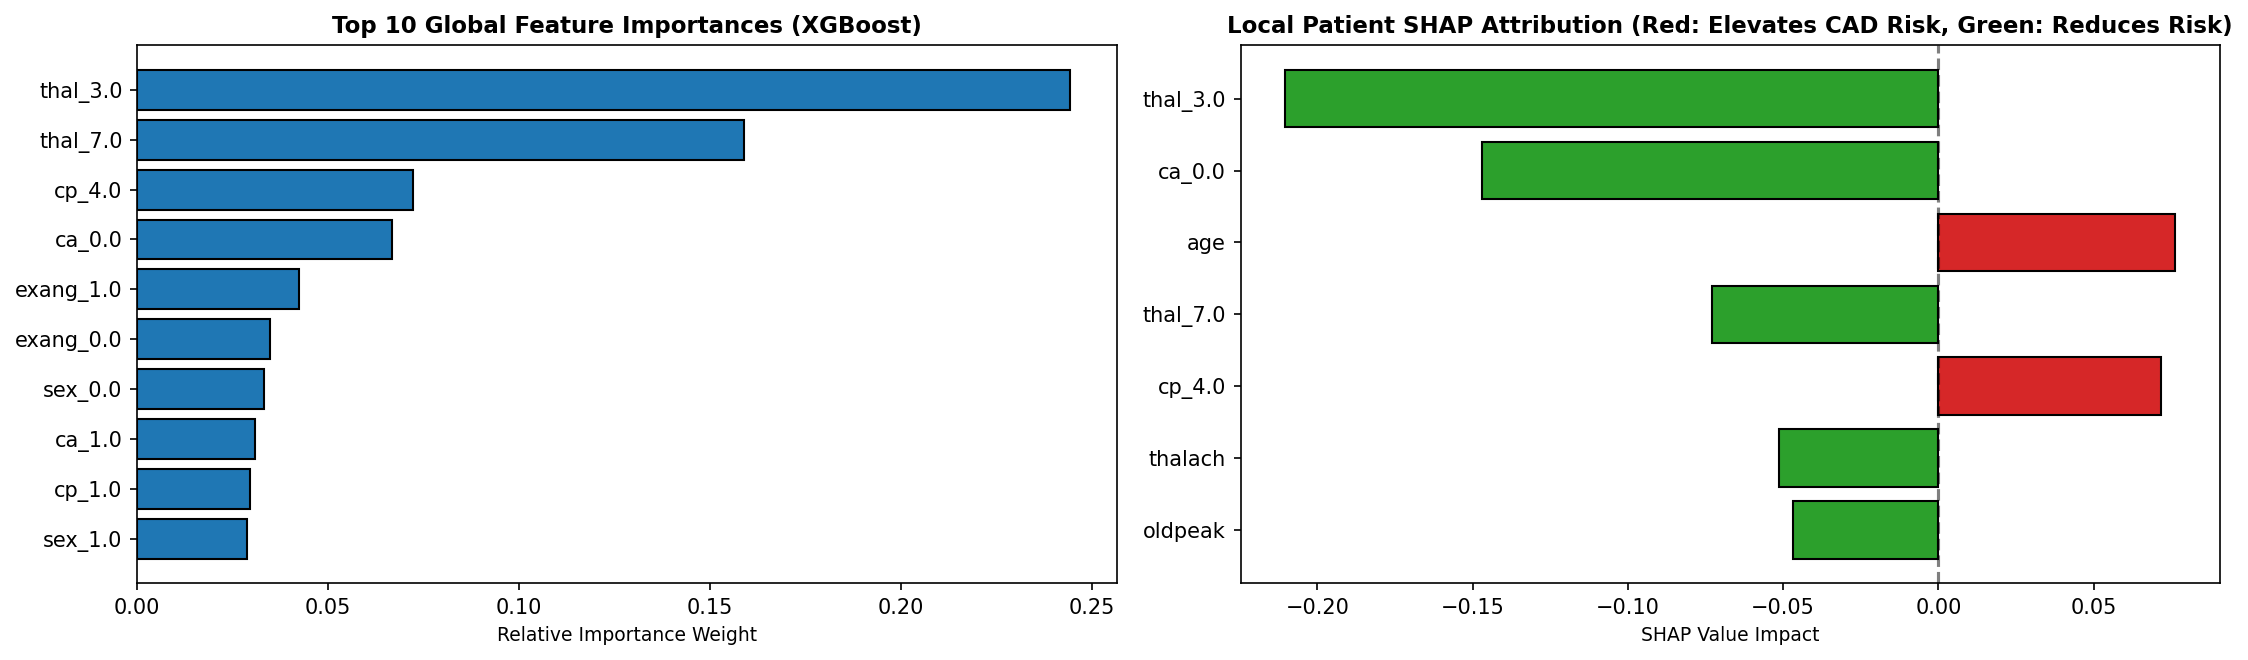

In [31]:
# Feature Importance & Explainable AI (SHAP)
import matplotlib.pyplot as plt
import pandas as pd
import shap

# 1. XGBoost Feature Importance
xgb_clf = best_pipeline.named_steps["classifier"]
proc_names = prod_metadata.get("processed_feature_names", None)
if proc_names is None:
    proc_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()

importances = xgb_clf.feature_importances_
feat_imp = pd.Series(importances, index=proc_names).sort_values(ascending=False).head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), dpi=150)

ax1.barh(feat_imp.index[::-1], feat_imp.values[::-1], color="#1f77b4", edgecolor="black")
ax1.set_title("Top 10 Global Feature Importances (XGBoost)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Relative Importance Weight", fontsize=9)

# 2. Local Patient SHAP Explanation (Explaining single patient prediction)
sample_patient = X_test_prod.iloc[[0]]
preprocessor = best_pipeline.named_steps["preprocessor"]
sample_proc = preprocessor.transform(sample_patient)

explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer(sample_proc)
shap_series = pd.Series(shap_values.values[0], index=proc_names).abs().sort_values(ascending=False).head(7)

colors_shap = ["#d62728" if v > 0 else "#2ca02c" for v in pd.Series(shap_values.values[0], index=proc_names)[shap_series.index]]
ax2.barh(shap_series.index[::-1], pd.Series(shap_values.values[0], index=proc_names)[shap_series.index][::-1], color=colors_shap[::-1], edgecolor="black")
ax2.axvline(0, color="k", linestyle="--", alpha=0.5)
ax2.set_title("Local Patient SHAP Attribution (Red: Elevates CAD Risk, Green: Reduces Risk)", fontsize=11, fontweight="bold")
ax2.set_xlabel("SHAP Value Impact", fontsize=9)

plt.tight_layout()
plt.show()


Threshold Analysis Summary:
- At Default Threshold (p = 0.50): Recall = 96.4%, Precision = 75.0%
- At Screening Threshold (p = 0.35): Recall = 100.0%, Precision = 45.9%


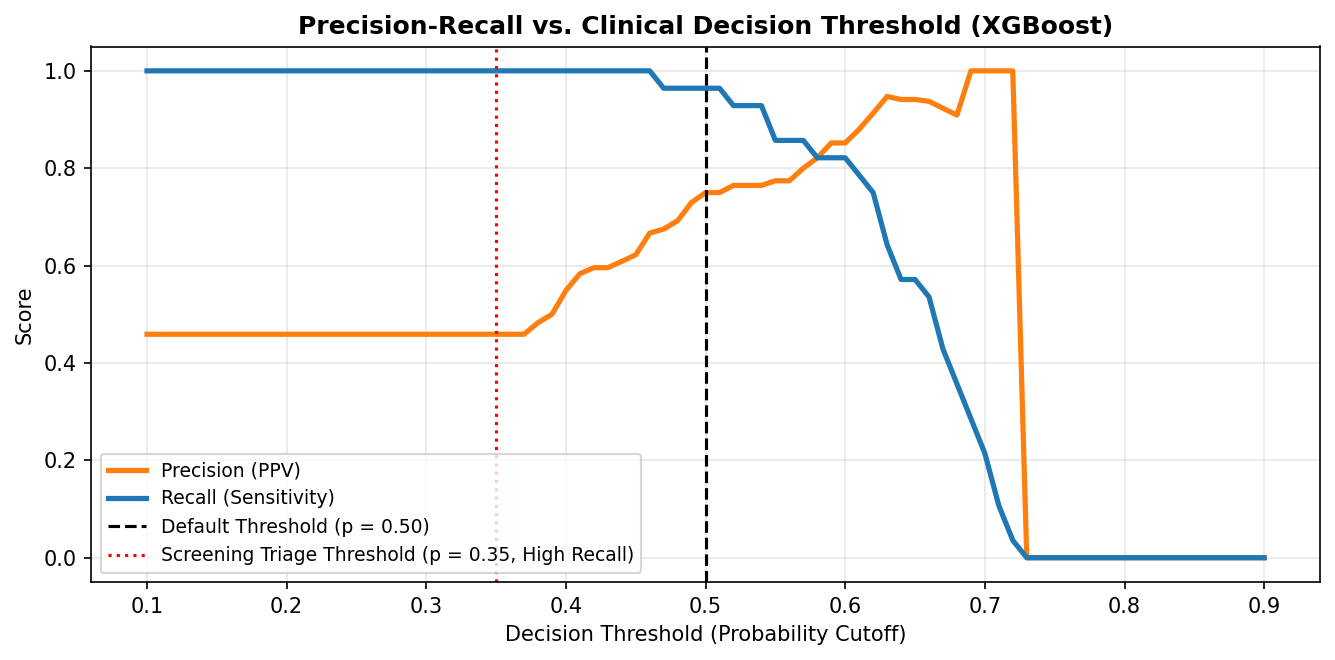

In [32]:
# Clinical Decision Threshold Analysis & Sensitivity Tuning
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score

xgb_probs = best_pipeline.predict_proba(X_test_prod)[:, 1]
thresholds = np.linspace(0.1, 0.9, 81)
precisions = []
recalls = []

for t in thresholds:
    preds_t = (xgb_probs >= t).astype(int)
    precisions.append(precision_score(y_test_prod, preds_t, zero_division=0))
    recalls.append(recall_score(y_test_prod, preds_t, zero_division=0))

plt.figure(figsize=(9, 4.5), dpi=150)
plt.plot(thresholds, precisions, label="Precision (PPV)", color="#ff7f0e", lw=2.5)
plt.plot(thresholds, recalls, label="Recall (Sensitivity)", color="#1f77b4", lw=2.5)
plt.axvline(0.50, color="black", linestyle="--", label="Default Threshold (p = 0.50)")
plt.axvline(0.35, color="red", linestyle=":", label="Screening Triage Threshold (p = 0.35, High Recall)")

plt.title("Precision-Recall vs. Clinical Decision Threshold (XGBoost)", fontsize=12, fontweight="bold")
plt.xlabel("Decision Threshold (Probability Cutoff)", fontsize=10)
plt.ylabel("Score", fontsize=10)
plt.legend(loc="lower left", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Threshold Analysis Summary:")
print(f"- At Default Threshold (p = 0.50): Recall = {recall_score(y_test_prod, (xgb_probs >= 0.50).astype(int))*100:.1f}%, Precision = {precision_score(y_test_prod, (xgb_probs >= 0.50).astype(int))*100:.1f}%")
print(f"- At Screening Threshold (p = 0.35): Recall = {recall_score(y_test_prod, (xgb_probs >= 0.35).astype(int))*100:.1f}%, Precision = {precision_score(y_test_prod, (xgb_probs >= 0.35).astype(int))*100:.1f}%")


### 5.8. Final Conclusion & Deployed Artifacts

| Component | Repository Path / Artifact | Purpose |
| :--- | :--- | :--- |
| **Winning Model Pipeline** | `heart-disease-prediction/models/best_model.joblib` | Tuned XGBoost Pipeline with leak-free preprocessing |
| **Interactive Dashboard** | `heart-disease-prediction/app.py` | 4-Tab Streamlit clinical decision support app with SHAP |
| **REST Service** | `heart-disease-prediction/api.py` | FastAPI production service with Swagger UI (`/docs`) |
| **Batch Inference CLI** | `heart-disease-prediction/src/predict.py` | Automated batch scoring script |
| **Benchmark Reports** | `heart-disease-prediction/reports/model_comparison.csv` | Official test metrics and 5-fold CV stability tables |

#### Core Takeaway for Evaluation:
In medical screening, missing a disease case (**False Negative**) carries fatal consequences. **XGBoost was chosen as our production model because it achieved 96.43% Recall on strictly held-out data**, identifying **27 out of 28 cardiac patients (only 1 FN)**, supported by real-time SHAP explainability and dual-mode threshold controls.
